In [3]:
import numpy as np
from matplotlib import pyplot as plt
from scipy import * 
from astropy.io import ascii
import gzip
from astropy.table import Table

In [4]:
GNOSIS_h1h2_throughput_path = '/Users/tliu/oh_suppression/data/FBG_data/h1h2model.txt'

In [ ]:
data = np.loadtxt(GNOSIS_h1h2_throughput_path)

print("Shape:", data.shape)
print("Rows:", data.shape[0])
print("Columns:", data.shape[1])

wavelength = data[:, 0]
throughput = data[:, 1]

In [11]:
import pandas as pd

df = pd.read_csv(
    GNOSIS_h1h2_throughput_path,
    sep=r"\s+",
    header=None,
    names=["wavelength", "throughput"]
)

print(df.shape)
print(df.head())

(105119, 2)
   wavelength  throughput
0     1.35000    0.940000
1     1.40000    0.940000
2     1.42058    0.945424
3     1.42058    0.944867
4     1.42059    0.947483


In [12]:
df

,wavelength,throughput
0,1.35000,0.940000
1,1.40000,0.940000
2,1.42058,0.945424
3,1.42058,0.944867
4,1.42059,0.947483
...,...,...
105114,1.72008,0.749917
105115,1.72009,0.940000
105116,1.80000,0.940000
105117,1.85000,0.940000


In [15]:
np.where?

Signature:       np.where(condition, x=None, y=None, /)
Call signature:  np.where(*args, **kwargs)
Type:            _ArrayFunctionDispatcher
String form:     <built-in function where>
Docstring:      
where(condition, [x, y], /)

Return elements chosen from `x` or `y` depending on `condition`.

.. note::
    When only `condition` is provided, this function is a shorthand for
    ``np.asarray(condition).nonzero()``. Using `nonzero` directly should be
    preferred, as it behaves correctly for subclasses. The rest of this
    documentation covers only the case where all three arguments are
    provided.

Parameters
----------
condition : array_like, bool
    Where True, yield `x`, otherwise yield `y`.
x, y : array_like
    Values from which to choose. `x`, `y` and `condition` need to be
    broadcastable to some shape.

Returns
-------
out : ndarray
    An array with elements from `x` where `condition` is True, and elements
    from `y` elsewhere.

See Also
--------
choose
nonzero : The 

In [63]:
# Find index number where wavelength is less than or equal to 1.7 microns
print("Index of the last wavelength point less than or equal to 1.7 microns:", np.where(wavelength <= 1.7)[0][-1])
# Find index number where wavelength is greater than or equal to 1.47 microns
print("Index of the first wavelength point greater than or equal to 1.465 microns:", np.where(wavelength >= 1.465)[0][0])


Index of the last wavelength point less than or equal to 1.7 microns: 96999
Index of the first wavelength point greater than or equal to 1.465 microns: 13470


In [64]:
wavelength = df["wavelength"]
throughput = df["throughput"]

In [73]:
# plt.figure(figsize=(15, 4))
# plt.plot(wavelength[14987-1:96999+1], throughput[14987-1:96999+1], linewidth=0.5) # +1 because the index is inclusive
# plt.xlabel("wavelength (µm)")
# plt.ylabel("throughput")

In [74]:
# # Plot y-axis in decibels (dB) using the formula: dB = 10 * log10(throughput)
# plt.figure(figsize=(16, 4))
# plt.plot(wavelength[13470-1:96999+1], 10 * np.log10(throughput[13470-1:96999+1]), linewidth=0.5) # +1 because the index is inclusive
# plt.xlabel("wavelength (µm)")
# plt.ylabel("Transmission (dB)")

Text(0, 0.5, 'Transmission (dB)')

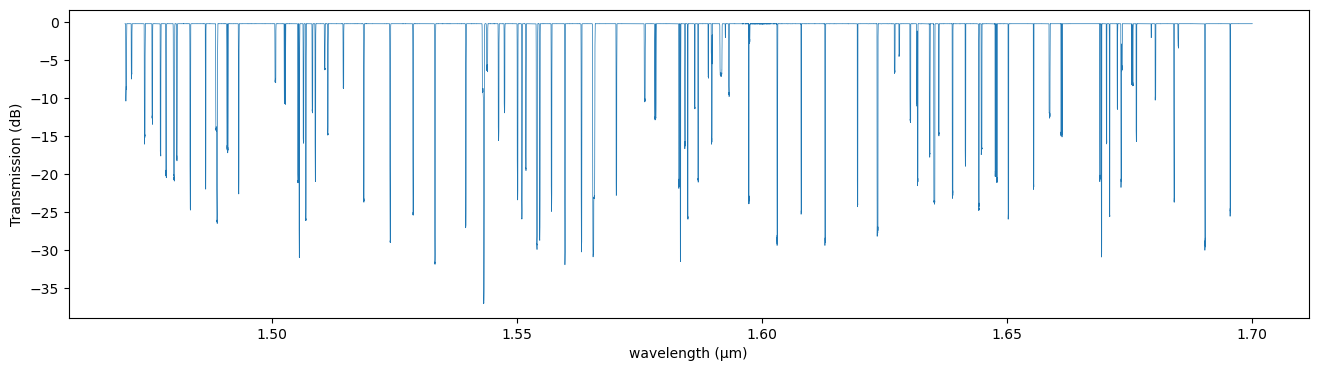

In [46]:
# Plot y-axis in decibels (dB) using the formula: dB = 10 * log10(throughput)
plt.figure(figsize=(16, 4))
plt.plot(wavelength[14987-1:96999+1], 10 * np.log10(throughput[14987-1:96999+1]), linewidth=0.5) # +1 because the index is inclusive
plt.xlabel("wavelength (µm)")
plt.ylabel("Transmission (dB)")

In [ ]:
print("Index of the first wavelength point greater than or equal to 1.58 microns:", np.where(wavelength >= 1.58)[0][0])

Index of the first wavelength point greater than or equal to 1.58 microns: 48494


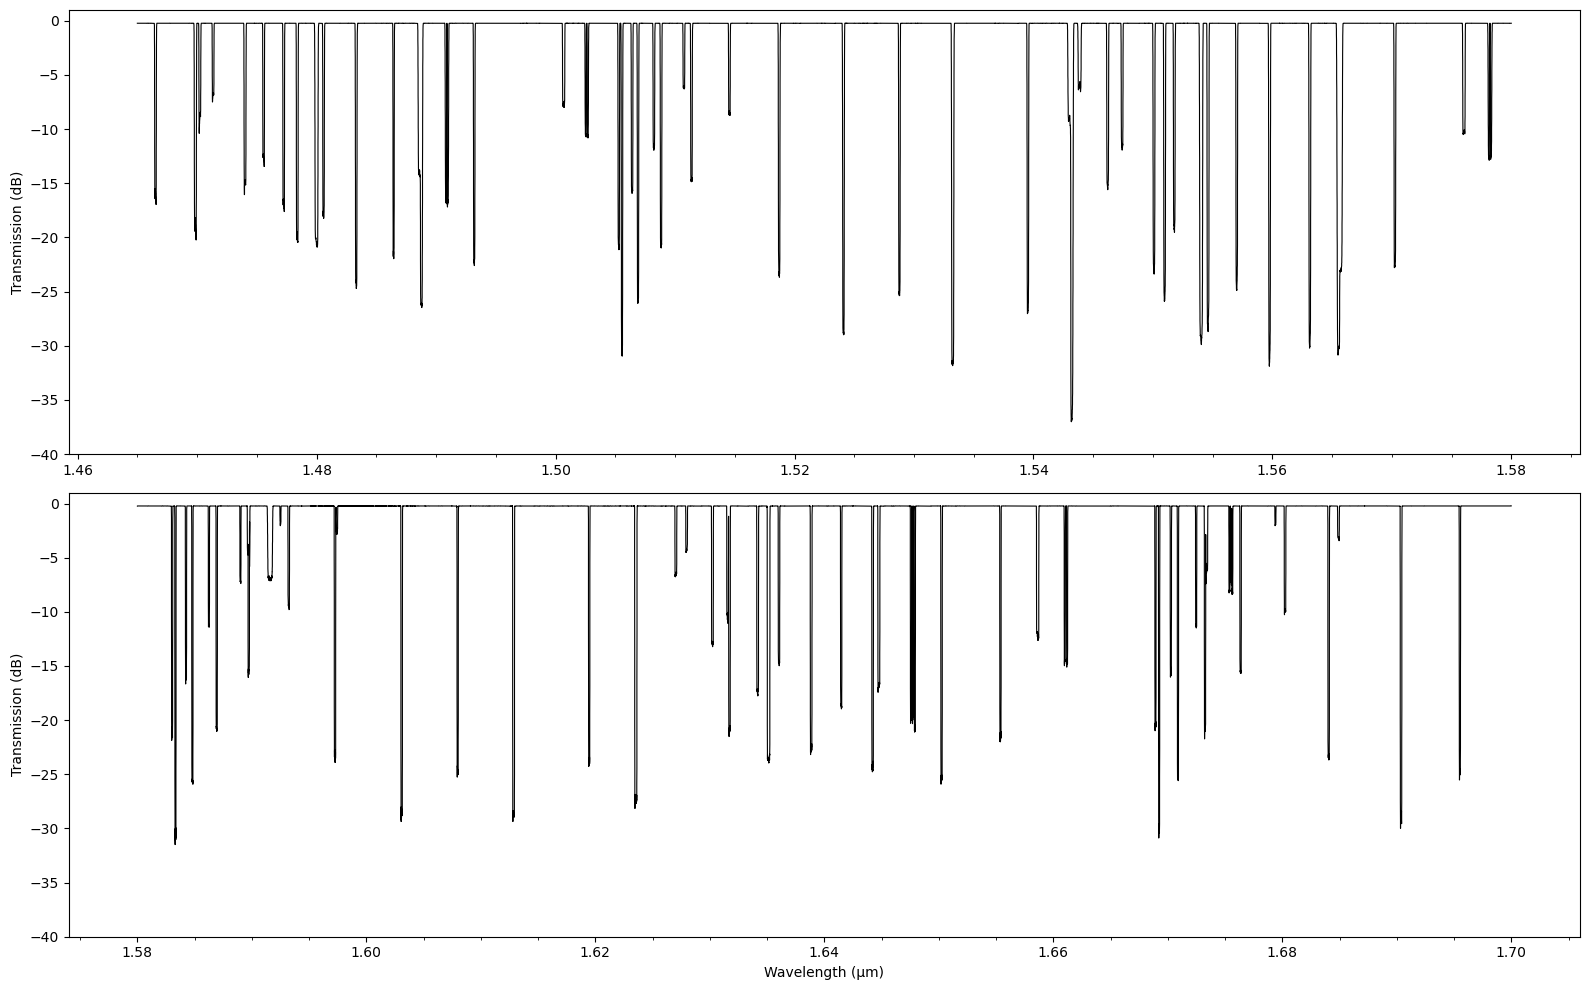

In [70]:
from matplotlib.ticker import MultipleLocator

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=False)

ax1.plot(
    wavelength[13470-1:48494+1],
    10 * np.log10(throughput[13470-1:48494+1]),
    linewidth=0.8, color='k'
)
ax1.set_ylim(-40, 1)
ax1.set_ylabel("Transmission (dB)")
ax1.xaxis.set_minor_locator(MultipleLocator(0.005))

ax2.plot(
    wavelength[48494+1:96999+1],
    10 * np.log10(throughput[48494+1:96999+1]),
    linewidth=0.8, color='k'
)
ax2.set_ylim(-40, 1)
ax2.set_xlabel("Wavelength (µm)")
ax2.set_ylabel("Transmission (dB)")
ax2.xaxis.set_minor_locator(MultipleLocator(0.005))

plt.tight_layout()
plt.show()

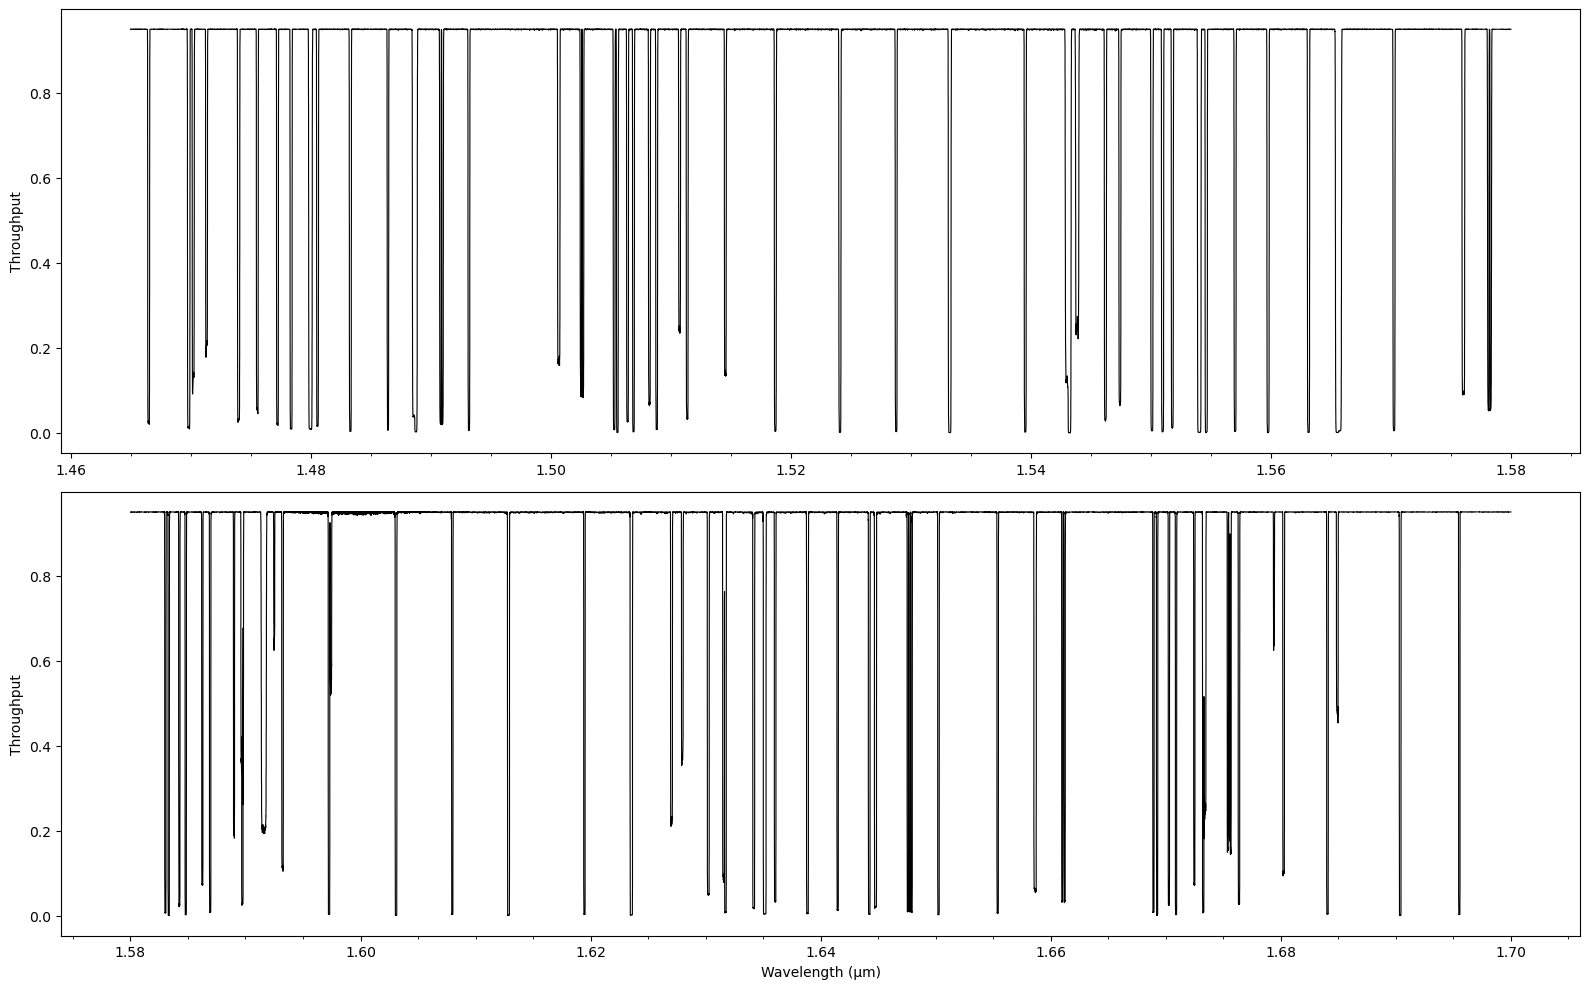

In [72]:
from matplotlib.ticker import MultipleLocator

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 10), sharex=False)

ax1.plot(
    wavelength[13470-1:48494+1],
    throughput[13470-1:48494+1],
    linewidth=0.8, color='k'
)
# ax1.set_ylim(-40, 1)
ax1.set_ylabel("Throughput")
ax1.xaxis.set_minor_locator(MultipleLocator(0.005))

ax2.plot(
    wavelength[48494+1:96999+1],
    throughput[48494+1:96999+1],
    linewidth=0.8, color='k'
)
# ax2.set_ylim(-40, 1)
ax2.set_xlabel("Wavelength (µm)")
ax2.set_ylabel("Throughput")
ax2.xaxis.set_minor_locator(MultipleLocator(0.005))

plt.tight_layout()
plt.show()

In [75]:
Rousselot_list_V2_file = '/Users/tliu/oh_suppression/data/OH_line_data/Rousellot_list_v2.0.dat'

Rousselot_list_V2 = np.loadtxt(Rousselot_list_V2_file)

In [76]:
Rousselot_list_V2

array([[6.13824e-01, 1.25800e+03],
       [6.13827e-01, 1.25800e+03],
       [6.13847e-01, 3.36100e+03],
       ...,
       [2.57866e+00, 5.15200e-02],
       [2.62297e+00, 2.49300e-03],
       [2.62401e+00, 2.49300e-03]], shape=(4732, 2))

In [79]:
# convert Rousselot_list_V2 to a pandas DataFrame for easier manipulation
Rousselot_df = pd.DataFrame(Rousselot_list_V2, columns=["wavelength", "intensity"])

In [80]:
Rousselot_df

,wavelength,intensity
0,0.613824,1258.000000
1,0.613827,1258.000000
2,0.613847,3361.000000
3,0.613850,3361.000000
4,0.613931,648.300000
...,...,...
4727,2.575730,0.035880
4728,2.577310,0.051520
4729,2.578660,0.051520
4730,2.622970,0.002493


Text(0, 0.5, 'intensity (?)')

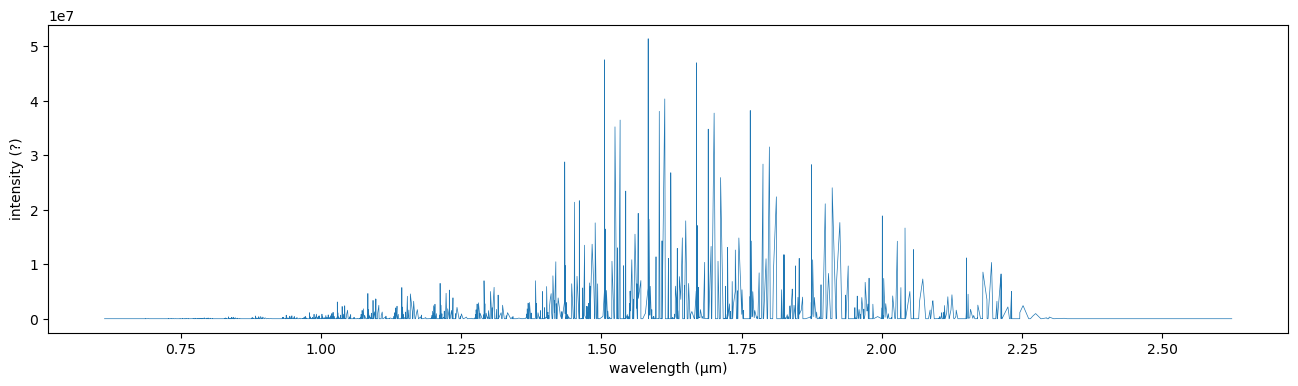

In [84]:
plt.figure(figsize=(16, 4))
plt.plot(Rousselot_df["wavelength"], Rousselot_df["intensity"], linewidth=0.5)
plt.xlabel("wavelength (µm)")
plt.ylabel("intensity (?)")

In [ ]:
rosed_SED_file = '/Users/tliu/oh_suppression/data/OH_line_data/rosed.dat'

# rosed_SED = np.genfromtxt(
#     rosed_SED_file,
#     skip_header=1,
#     comments="#",
#     invalid_raise=False
# )

In [91]:
# # print first 50 rows of rosed_SED to check the data
# print(rosed_SED[:50])

In [92]:
with open(rosed_SED_file) as f:
    for i in range(20):
        print(repr(f.readline()))

'1\t0\n'
'10000001/10000000\t0\n'
'5000001/5000000\t0\n'
'10000003/10000000\t0\n'
'2500001/2500000\t0\n'
'2000001/2000000\t0\n'
'5000003/5000000\t0\n'
'10000007/10000000\t0\n'
'1250001/1250000\t0\n'
'10000009/10000000\t0\n'
'1000001/1000000\t0\n'
'10000011/10000000\t0\n'
'2500003/2500000\t0\n'
'10000013/10000000\t0\n'
'5000007/5000000\t0\n'
'2000003/2000000\t0\n'
'625001/625000\t0\n'
'10000017/10000000\t0\n'
'5000009/5000000\t0\n'
'10000019/10000000\t0\n'


In [ ]:
from fractions import Fraction
import pandas as pd

rosed_SED = pd.read_csv(
    rosed_SED_file,
    sep="\t",
    header=None,
    names=["wavelength", "flux"],
    converters={"wavelength": lambda x: float(Fraction(x))}
)

rosed_SED["flux"] = pd.to_numeric(rosed_SED["flux"])

print(rosed_SED.shape)
print(rosed_SED.head(50))

(10000001, 2)
    wavelength  flux
0     1.000000   0.0
1     1.000000   0.0
2     1.000000   0.0
3     1.000000   0.0
4     1.000000   0.0
5     1.000001   0.0
6     1.000001   0.0
7     1.000001   0.0
8     1.000001   0.0
9     1.000001   0.0
10    1.000001   0.0
11    1.000001   0.0
12    1.000001   0.0
13    1.000001   0.0
14    1.000001   0.0
15    1.000001   0.0
16    1.000002   0.0
17    1.000002   0.0
18    1.000002   0.0
19    1.000002   0.0
20    1.000002   0.0
21    1.000002   0.0
22    1.000002   0.0
23    1.000002   0.0
24    1.000002   0.0
25    1.000002   0.0
26    1.000003   0.0
27    1.000003   0.0
28    1.000003   0.0
29    1.000003   0.0
30    1.000003   0.0
31    1.000003   0.0
32    1.000003   0.0
33    1.000003   0.0
34    1.000003   0.0
35    1.000004   0.0
36    1.000004   0.0
37    1.000004   0.0
38    1.000004   0.0
39    1.000004   0.0
40    1.000004   0.0
41    1.000004   0.0
42    1.000004   0.0
43    1.000004   0.0
44    1.000004   0.0
45    1.000004   0.0

In [95]:
wavelength_rosed = rosed_SED["wavelength"].to_numpy()
flux_rosed = rosed_SED["flux"].to_numpy()

Text(0, 0.5, 'intensity (?)')

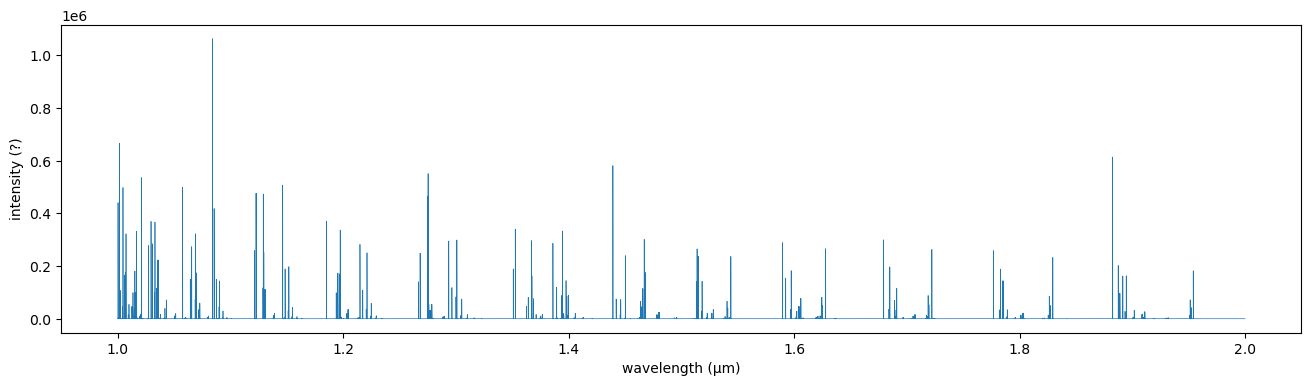

In [96]:
plt.figure(figsize=(16, 4))
plt.plot(wavelength_rosed, flux_rosed, linewidth=0.5)
plt.xlabel("wavelength (µm)")
plt.ylabel("intensity (?)")

In [ ]:
rosed2zslilcatmostel_file = '/Users/tliu/oh_suppression/data/OH_line_data/rosed2zslilcatmostel.dat'

with open(rosed2zslilcatmostel_file) as f:
    for i in range(20):
        print(repr(f.readline()))

In [104]:
rosed2 = pd.read_csv(
    rosed2zslilcatmostel_file,
    sep="\t",
    header=None,
    names=["wavelength", "flux"],
    converters={"wavelength": lambda value: float(Fraction(value))}
)

rosed2["flux"] = pd.to_numeric(rosed2["flux"])

print("Shape:", rosed2.shape)
print(rosed2.head())
print(rosed2.dtypes)

wavelength_rosed2plus = rosed2["wavelength"].to_numpy()
flux_rosed2plus = rosed2["flux"].to_numpy()

Shape: (10000001, 2)
   wavelength        flux
0         1.0  616.968202
1         1.0  616.968211
2         1.0  616.968220
3         1.0  616.968230
4         1.0  616.968239
wavelength    float64
flux          float64
dtype: object


Text(0, 0.5, 'intensity (?)')

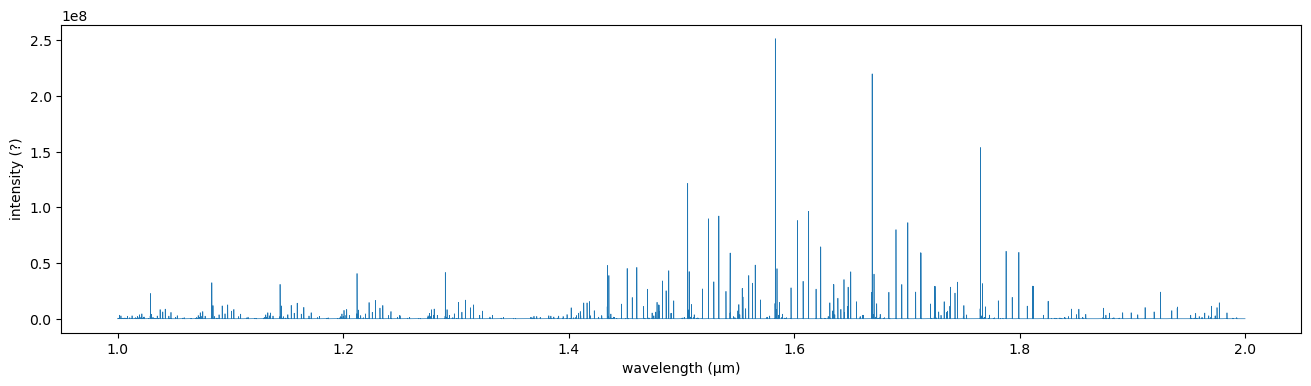

In [105]:
plt.figure(figsize=(16, 4))
plt.plot(wavelength_rosed2plus, flux_rosed2plus, linewidth=0.5)
plt.xlabel("wavelength (µm)")
plt.ylabel("intensity (?)")